In [ ]:
import sys
sys.path.append('..')
from setup import *
from cca import *
from clustering import fit_gmm
from collections import Counter

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
base_model_paths = list(subdirs('saved_models/gv_run/', start="r"))
# low_rank fits inherit (dead) attributes from OG models
base_models = [load_rnn(path)[0] for path in base_model_paths]
_, _, task_params, training_params = load_rnn(base_model_paths[0])
training_params["lr"] = .0001

In [ ]:
sortby = "w_in_scale" # toggle for sorting in different ways
sortedIdxs = np.argsort([base_model.params[sortby] for base_model in base_models])
sortedModels = [base_models[i] for i in sortedIdxs]

# load refs
model_rev_eng_pops, _, _, training_params = load_rnn("saved_models/mf_pop_dyn_chols_no_In") 
model_rev_eng_sharing, *_ = load_rnn("saved_models/lr_model_rrr") #rrr distil

# first one is the meanfield. All other models of this had different sizes: 
N = base_models[0].params["recurrent_size"]

# first one is the meanfield. All other models of this had different sizes: 
N = base_models[0].params["recurrent_size"]
pops = np.zeros(N)
pops[:int(N / 2)] = 1
resampled = resample(model_rev_eng_pops, N, pops=pops)
train_rnn(resampled, cycles, training_params)
sortedModels += [resampled, model_rev_eng_sharing]

(8, 256)
epoch 443 / 10000	time=57.00189s	task_loss=0.009872952708974485
Done: training took 57.0 sec.


Counter({1: 129, 0: 127})
Counter({1: 129, 0: 127})
Counter({1: 129, 0: 127})
Counter({1: 129, 0: 127})


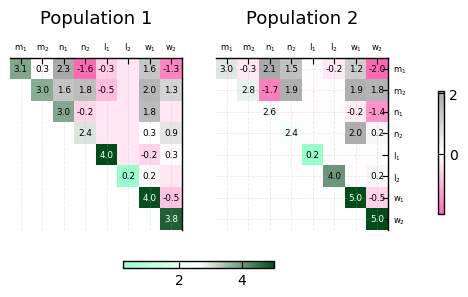

In [20]:
# sanity check 
conn_vecs = get_model_conn_vecs(resampled)
for _ in range(4):
    pops, gmm = fit_gmm(conn_vecs.T, n_components=2)
    print(Counter(pops))

covs = get_overlap_matrix_all_params(conn_vecs, pops=pops)
lower_triangular_heatmap(covs,
                         labels=build_labels(resampled),
                         put_text=True)

plt.show()

In [21]:
# get the CCA targets:
from Tasks import cycling
cycles = Task.load_task("Cycling", task_params)
inputs = cycles.generate_inputs(NUM_ANGLES)

cca_targets = []
for base_model in sortedModels:
    rates, _ = run_rnn(base_model, inputs)
    cca_targets.append(rates)
cca_targets = np.array(cca_targets)

In [22]:
cca_sim = np.zeros((len(sortedModels), len(sortedModels)))
for i in range(len(sortedModels)):
    for j in range(i + 1, len(sortedModels)):

        res = pairwise_cca(
            cca_targets[i,...],
            cca_targets[j, ...],
            n_components=4,
            cca_dim=4,
        )
        cca_sim[i,j] = cca_sim[j, i] = np.mean(res["corr_coeff_"])

In [23]:
# prep plotting with nice blockwise annotations
blocks = [fr"$\sigma_I$ = {base_models[idx].params["w_in_scale"]}" for idx in sortedIdxs]
block_sizes = [v for k, v in Counter(blocks).items()]
keys = np.unique(blocks)
block_dict = dict(zip(keys, block_sizes))

block_triples = []
curr_size = 0
for idx in range(len(block_sizes)):
    curr_block_size = block_sizes[idx]
    block_triples.append((curr_size, curr_size + curr_block_size - 1,  keys[idx]))
    curr_size += curr_block_size 

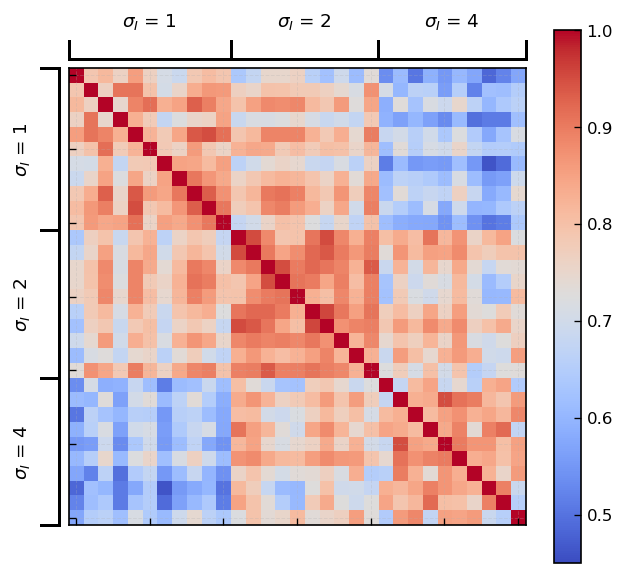

In [25]:
sims = cca_sim[:31, :31]
def add_top_bracket(ax, start, end, label, y=1.02, h=0.04, text_offset=0.02, lw=1.8):
    """
    Draw a bracket above columns [start, end] (inclusive).
    x is in data coordinates, y is in axes coordinates.
    """
    trans = ax.get_xaxis_transform()

    x0 = start - 0.5
    x1 = end + 0.5

    ax.plot([x0, x1], [y, y], color='black', lw=lw, transform=trans, clip_on=False)

    ax.plot([x0, x0], [y, y + h], color='black', lw=lw, transform=trans, clip_on=False)
    ax.plot([x1, x1], [y, y + h], color='black', lw=lw, transform=trans, clip_on=False)

    ax.text((x0 + x1) / 2, y + h + text_offset, label,
            ha='center', va='bottom', transform=trans)

def add_left_bracket(ax, start, end, label, x=-0.02, w=0.04, text_offset=0.02, lw=1.8):
    """
    Draw a bracket to the left of rows [start, end] (inclusive).
    y is in data coordinates, x is in axes coordinates.
    """
    trans = ax.get_yaxis_transform()

    y0 = start - 0.5
    y1 = end + 0.5

    # vertical line
    ax.plot([x, x], [y0, y1], color='black', lw=lw, transform=trans, clip_on=False)
    # small horizontal ticks
    ax.plot([x, x - w], [y0, y0], color='black', lw=lw, transform=trans, clip_on=False)
    ax.plot([x, x - w], [y1, y1], color='black', lw=lw, transform=trans, clip_on=False)

    ax.text(x - w - text_offset, (y0 + y1) / 2, label,
            ha='right', va='center', rotation=90, transform=trans)

# Example matrix
np.fill_diagonal(sims, 1.0)

with plotstyle.context("inputs", NUM_ANGLES):
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    im = ax.imshow(sims, vmin=0.45, vmax=1.0)
    fig.colorbar(im, ax=ax)


for s, e, lab in block_triples:
    add_top_bracket(ax, s, e, lab)
    add_left_bracket(ax, s, e, lab)

# give the brackets room
plt.subplots_adjust(top=0.85, left=0.22)
plt.show()

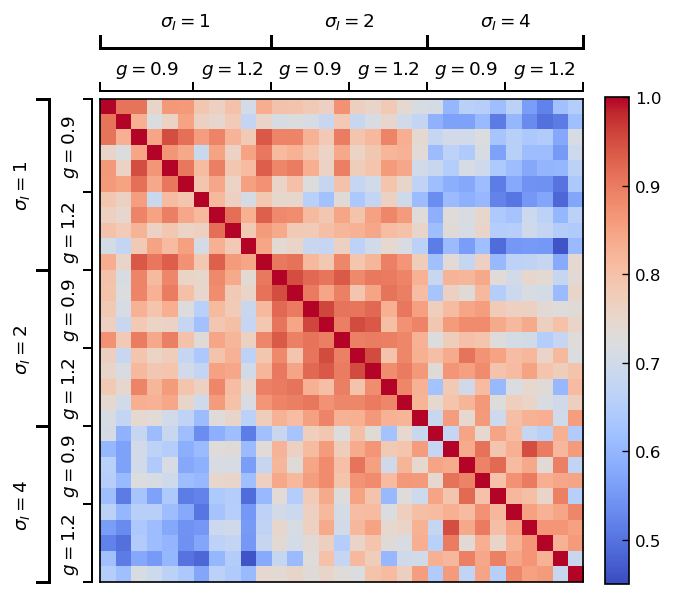

In [26]:
current_idxs = np.array(sortedIdxs[:31])

s_vals_current = np.array([
    base_models[idx].params["w_in_scale"]
    for idx in current_idxs
])

g_vals_current = np.array([
    base_models[idx].params["spectral_radius"]
    for idx in current_idxs
])

perm = np.lexsort((g_vals_current, s_vals_current))

sortedIdxs_hier = current_idxs[perm]

sims = cca_sim[:31, :31].copy()
sims = sims[np.ix_(perm, perm)]

np.fill_diagonal(sims, 1.0)

s_vals = np.array([
    base_models[idx].params["w_in_scale"]
    for idx in sortedIdxs_hier
])

g_vals = np.array([
    base_models[idx].params["spectral_radius"]
    for idx in sortedIdxs_hier
])


def find_contiguous_blocks(values):

    values = np.asarray(values)

    blocks = []
    start = 0

    for i in range(1, len(values)):

        if values[i] != values[i - 1]:

            blocks.append(
                (start, i - 1, values[start])
            )

            start = i

    blocks.append(
        (start, len(values) - 1, values[start])
    )

    return blocks

s_block_triples = find_contiguous_blocks(s_vals)


g_block_triples = []

for s_start, s_end, s in s_block_triples:

    g_sub = g_vals[s_start:s_end + 1]

    for g_start, g_end, g in find_contiguous_blocks(g_sub):

        g_block_triples.append(
            (
                s_start + g_start,
                s_start + g_end,
                g
            )
        )

def add_top_bracket(
    ax, start, end, label,
    y=1.02, h=0.025,
    text_offset=0.01,
    lw=1.5,
    fontsize=None
):

    trans = ax.get_xaxis_transform()

    x0 = start - 0.5
    x1 = end + 0.5

    ax.plot(
        [x0, x1], [y, y],
        color="black",
        lw=lw,
        transform=trans,
        clip_on=False
    )

    ax.plot(
        [x0, x0], [y, y + h],
        color="black",
        lw=lw,
        transform=trans,
        clip_on=False
    )

    ax.plot(
        [x1, x1], [y, y + h],
        color="black",
        lw=lw,
        transform=trans,
        clip_on=False
    )

    ax.text(
        (x0 + x1) / 2,
        y + h + text_offset,
        label,
        ha="center",
        va="bottom",
        fontsize=fontsize,
        transform=trans
    )


def add_left_bracket(
    ax, start, end, label,
    x=-0.02, w=0.025,
    text_offset=0.01,
    lw=1.5,
    fontsize=None
):

    trans = ax.get_yaxis_transform()

    y0 = start - 0.5
    y1 = end + 0.5

    ax.plot(
        [x, x], [y0, y1],
        color="black",
        lw=lw,
        transform=trans,
        clip_on=False
    )

    ax.plot(
        [x, x - w], [y0, y0],
        color="black",
        lw=lw,
        transform=trans,
        clip_on=False
    )

    ax.plot(
        [x, x - w], [y1, y1],
        color="black",
        lw=lw,
        transform=trans,
        clip_on=False
    )

    ax.text(
        x - w - text_offset,
        (y0 + y1) / 2,
        label,
        ha="right",
        va="center",
        rotation=90,
        fontsize=fontsize,
        transform=trans
    )

with plotstyle.context("inputs", NUM_ANGLES):

    fig, ax = plt.subplots(figsize=(7, 6))

    im = ax.imshow(
        sims,
        vmin=0.45,
        vmax=1.0
    )

    ax.set_xticks([])
    ax.set_yticks([])


    # INNER = g
    for start, end, g in g_block_triples:

        label = rf"$g={g:g}$"

        add_top_bracket(
            ax,
            start,
            end,
            label,
            y=1.015,
            h=0.018,
            text_offset=0.006,
            lw=1.2
        )

        add_left_bracket(
            ax,
            start,
            end,
            label,
            x=-0.015,
            w=0.018,
            text_offset=0.006,
            lw=1.2
        )


    # OUTER = sigma_I
    for start, end, s in s_block_triples:

        label = rf"$\sigma_I={s:g}$"

        add_top_bracket(
            ax,
            start,
            end,
            label,
            y=1.105,
            h=0.025,
            text_offset=0.01,
            lw=1.8
        )

        add_left_bracket(
            ax,
            start,
            end,
            label,
            x=-0.105,
            w=0.025,
            text_offset=0.01,
            lw=1.8
        )


    fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

    plt.subplots_adjust(
        top=0.80,
        left=0.27
    )
    #plt.savefig('Figures/Figures_4/solutions_hyperp.png')
    plt.show()

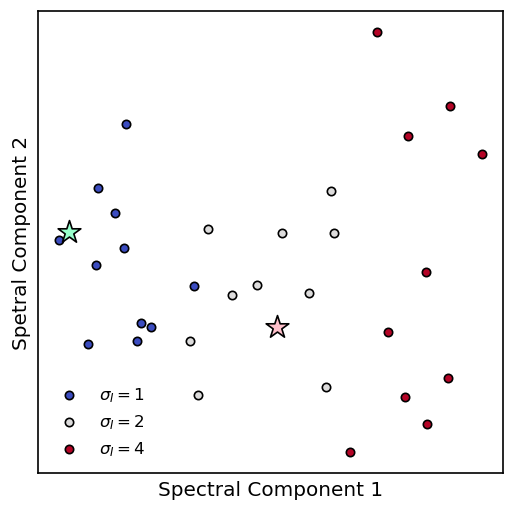

In [29]:
X = get_spectral_embedding(cca_sim)

with plotstyle.context("inputs", 3):
    fig = plt.figure(figsize=(5,5))
    labels = [model.params[sortby] for model in sortedModels[:31]]
    indicators = np.unique(labels)
    colors = get_colors(len(indicators))
    color_dict = dict(zip(indicators, colors)) 
    colors = np.asarray([color_dict[model.params[sortby]] for model in sortedModels[:31]])

    ax = fig.add_subplot(111)
    X_temp = X[:-2,:]
    for g in np.unique(labels):
        idx = labels == g
        ax.scatter(X_temp[idx, 0],
                   X_temp[idx, 1],
                   s=25,
                   edgecolors="black",
                   label=fr"$\sigma_I = {g}$")
        
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("Spectral Component 1")
    ax.set_ylabel("Spetral Component 2")

    # now scatter the extra two models:
    ax.scatter(
            X[-2, 0],
            X[-2, 1],
            s=205,
            marker="*",
            color="pink",
            edgecolor="black"
    )

    ax.scatter(
            X[-1, 0],
            X[-1, 1],
            s=205,
            marker="*",
            color="#98ffcc",
            edgecolor="black"
    )

    ax.legend(loc="lower left")
    plt.savefig('Figures/Figures_4/spectral_embedding_2.png')
    plt.show()
